# Passau MedCo · Exploratory Data Analysis

Who makes up the workforce, and in which groups are exits more frequent? One row represents one employee in the fictional IBM HR snapshot. The workforce profile describes the full CSV. The two comparisons that informed the model experiments use only the fixed training partition.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split

## 1. Can we use one row per employee?

The source pads headers and some values with spaces. Strip text before checking IDs, target labels, empty fields and duplicated records. The code below also checks whether the performance rating adds information beyond the pay increase.

In [2]:
csv_path = Path("data") / "employee-attrition.csv"
employees = pd.read_csv(csv_path)
employees.columns = employees.columns.str.strip()
for column in employees.select_dtypes(include="str"):
    employees[column] = employees[column].str.strip().replace("", pd.NA)

In [3]:
target_labels = set(employees["Attrition"].dropna())
quality_checks = pd.Series({
    "Missing values": employees.isna().sum().sum(),
    "Duplicate rows": employees.duplicated().sum(),
    "Duplicate employee IDs": employees["EmployeeNumber"].duplicated().sum(),
    "Missing employee IDs": employees["EmployeeNumber"].isna().sum(),
    "Missing target labels": employees["Attrition"].isna().sum(),
})
display(quality_checks.to_frame("Count"))
print("Target labels:", sorted(target_labels))

assert quality_checks.eq(0).all(), "Review duplicates, IDs, or missing labels."
assert target_labels == {"Yes", "No"}, "Review the Attrition labels."

# Check for redundant information in two recorded features.
rating_from_hike = 3 + employees["PercentSalaryHike"].ge(20).astype(int)
rating_matches = employees["PerformanceRating"].eq(rating_from_hike).sum()
print(f"Ratings matching the 20% salary-increase rule: {rating_matches:,} of {len(employees):,}")

,Count
Missing values,0
Duplicate rows,0
Duplicate employee IDs,0
Missing employee IDs,0
Missing target labels,0


Target labels: ['No', 'Yes']
Ratings matching the 20% salary-increase rule: 1,470 of 1,470


### Which numbers are codes?

The table distinguishes ordered codes from measurements, counts and nominal labels. For short scales it shows all observed values. Education runs from 1 to 5; satisfaction, involvement and work-life balance run from 1 to 4. An increase of one category need not represent an equal change in exit risk. The rate fields have no documented unit in this CSV.

In [4]:
ordered = {
    "Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel", "JobSatisfaction",
    "PerformanceRating", "RelationshipSatisfaction", "StockOptionLevel", "WorkLifeBalance",
}
counts = {"NumCompaniesWorked", "TrainingTimesLastYear"}
constants = employees.columns[employees.nunique(dropna=False).eq(1)].tolist()
kinds = {
    **dict.fromkeys(employees.select_dtypes("number"), "Measurement"),
    **dict.fromkeys(employees.select_dtypes("str"), "Nominal category"),
    **dict.fromkeys(ordered, "Ordered code"),
    **dict.fromkeys(counts, "Count"),
    **dict.fromkeys(constants, "Constant"),
    "Attrition": "Target (Yes = left)", "EmployeeNumber": "Employee ID",
}
schema = pd.DataFrame({"Meaning": pd.Series(kinds), "Distinct": employees.nunique()})
schema["Observed values or range"] = [
    ", ".join(map(str, sorted(s.unique()))) if s.nunique() <= 10
    else f"{s.min():,} to {s.max():,}"
    for _, s in employees[schema.index].items()
]
display(schema.sort_index())

,Meaning,Distinct,Observed values or range
Age,Measurement,43,18 to 60
Attrition,Target (Yes = left),2,"No, Yes"
BusinessTravel,Nominal category,3,"Non-Travel, Travel_Frequently, Travel_Rarely"
DailyRate,Measurement,886,"102 to 1,499"
Department,Nominal category,3,"Human Resources, Research & Development, Sales"
DistanceFromHome,Measurement,29,1 to 29
Education,Ordered code,5,"1, 2, 3, 4, 5"
EducationField,Nominal category,6,"Human Resources, Life Sciences, Marketing, Med..."
EmployeeCount,Constant,1,1
EmployeeNumber,Employee ID,1470,"1 to 2,068"


In [5]:
# EmployeeNumber identifies rows and was used above to check for missing or duplicate IDs.
# EmployeeCount (1), Over18 (Y), and StandardHours (80) are constant across employees,
# so they provide no variation for group comparisons.
excluded_columns = ["EmployeeNumber", *constants]
eda = employees.drop(columns=excluded_columns).copy()
eda["LeftCompany"] = eda["Attrition"].eq("Yes")
eda["TenureBand"] = pd.cut(
    eda["YearsAtCompany"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=["0–2", "3–5", "6–10", "11+"],
)

eda["AgeBand"] = pd.cut(eda["Age"], [0, 24, 34, 44, 54, float("inf")],
                        labels=["≤24", "25–34", "35–44", "45–54", "55+"])
eda["ManagerTenure"] = eda["YearsWithCurrManager"].eq(0).map(
    {True: "0 completed years", False: "1+ completed years"}
)

print("Excluded columns:", ", ".join(excluded_columns))
print(f"{len(eda):,} employees retained")

Excluded columns: EmployeeNumber, EmployeeCount, Over18, StandardHours
1,470 employees retained


## 2. Who is in the workforce?

The exit share gives the reference level for later comparisons. Four selected measurements describe age, pay, tenure and commute distance.

In [6]:
attrition_counts = eda["Attrition"].value_counts().reindex(["No", "Yes"])
attrition_summary = attrition_counts.to_frame("Employees")
attrition_summary["Share (%)"] = 100 * attrition_counts / len(eda)
overall_rate = attrition_summary.loc["Yes", "Share (%)"]
display(attrition_summary.round(1))

numeric_features = ["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome"]
display(eda[numeric_features].describe().T.round(1))

,Employees,Share (%)
Attrition,,
No,1233,83.9
Yes,237,16.1


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.9,9.1,18.0,30.0,36.0,43.0,60.0
MonthlyIncome,1470.0,6502.9,4708.0,1009.0,2911.0,4919.0,8379.0,19999.0
YearsAtCompany,1470.0,7.0,6.1,0.0,3.0,5.0,9.0,40.0
DistanceFromHome,1470.0,9.2,8.1,1.0,2.0,7.0,14.0,29.0


**Reading the group tables.** The column **“Why read this rate with care?”**, highlights groups where one person can make a noticeable difference. The note gives the actual count whenever a group has fewer than 30 employees, fewer than five who left, or fewer than five who stayed. A dash (—) means the group meets all three minimum counts.

In [7]:
def summarize_attrition(group_columns, frame=eda):
    summary = (
        frame.groupby(group_columns, observed=True, dropna=False)
        .agg(
            **{
                "Employees": ("LeftCompany", "size"),
                "Employees who left": ("LeftCompany", "sum"),
            }
        )
    )
    summary["Attrition (%)"] = 100 * summary["Employees who left"] / summary["Employees"]
    notes = []
    for total, left in zip(summary["Employees"], summary["Employees who left"]):
        reasons = []
        if total < 30:
            reasons.append(f"only {total} employees")
        if left < 5:
            reasons.append(f"only {left} left")
        if total - left < 5:
            reasons.append(f"only {total - left} stayed")
        notes.append(" · ".join(reasons) or "—")
    summary["Why read this rate with care?"] = notes
    return summary

### Describe the workforce by department

Compare department sizes, typical tenure, and the share of employees who work overtime.

In [8]:
department_profile = summarize_attrition("Department").join(
    eda.assign(WorksOvertime=eda["OverTime"].eq("Yes")).groupby("Department").agg(
        **{"Median tenure (years)": ("YearsAtCompany", "median"),
           "Overtime share (%)": ("WorksOvertime", "mean")}
    )
).sort_values("Employees", ascending=False)
department_profile["Overtime share (%)"] *= 100
department_profile["Workforce share (%)"] = 100 * department_profile["Employees"] / len(eda)
display(department_profile.round(1))

,Employees,Employees who left,Attrition (%),Why read this rate with care?,Median tenure (years),Overtime share (%),Workforce share (%)
Department,,,,,,,
Research & Development,961,133,13.8,—,5.0,28.2,65.4
Sales,446,92,20.6,—,6.0,28.7,30.3
Human Resources,63,12,19.0,—,5.0,27.0,4.3


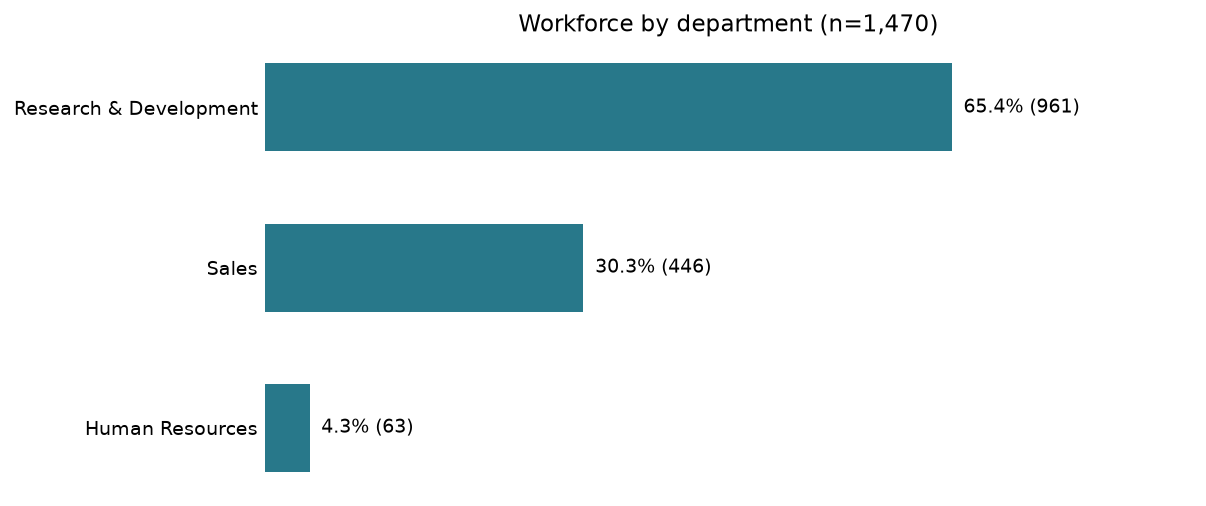

In [9]:
%matplotlib inline

fig, ax = plt.subplots(figsize=(8.5, 3.5), dpi=140, layout="constrained")
shares = department_profile["Workforce share (%)"]
bars = ax.barh(shares.index, shares, color="#28788a", height=0.55)
ax.invert_yaxis()
ax.bar_label(
    bars,
    labels=[
        f"{share:.1f}% ({count:,})"
        for share, count in zip(shares, department_profile["Employees"])
    ],
    padding=6,
)
ax.set(
    title=f"Workforce by department (n={len(eda):,})",
    xlim=(0, shares.max() * 1.35),
    xticks=[],
)
ax.tick_params(axis="y", length=0)
ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
plt.show()

### Compare medians by attrition status

Compare typical age, income, tenure, and commute distance for employees who left or stayed.

In [10]:
medians = eda.groupby("Attrition")[numeric_features].median()
display(medians.rename(index={"No": "Stayed", "Yes": "Left"}))

,Age,MonthlyIncome,YearsAtCompany,DistanceFromHome
Attrition,,,,
Stayed,36.0,5204.0,6.0,7.0
Left,32.0,3202.0,3.0,9.0


### Compare income and tenure distributions by attrition status

The boxes show the middle 50% of each group, and the line inside each box marks the median. Points beyond the whiskers are individual observations.

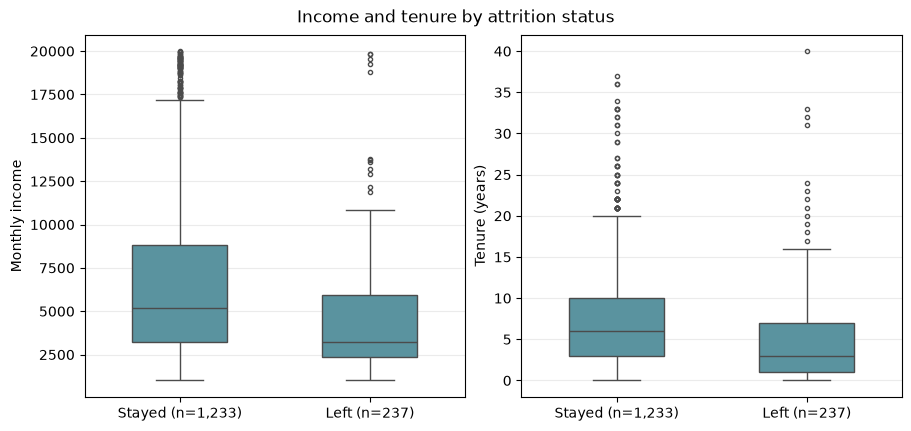

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), layout="constrained")
group_order = ["No", "Yes"]
group_labels = [f"Stayed (n={attrition_counts['No']:,})", f"Left (n={attrition_counts['Yes']:,})"]

for ax, column, label in zip(
    axes, ["MonthlyIncome", "YearsAtCompany"], ["Monthly income", "Tenure (years)"]
):
    sns.boxplot(
        data=eda, x="Attrition", y=column, order=group_order,
        color="#4e9aab", width=0.5, fliersize=3, ax=ax,
    )
    ax.set(xlabel="", ylabel=label)
    ax.set_xticks([0, 1], group_labels)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle("Income and tenure by attrition status")
plt.show()

Employees who left had lower median income and shorter median tenure. The middle halves still overlap for both measures. For tenure, the middle half spans 1–7 years among employees who left and 3–10 years among those who stayed.

### Compare monthly income within job levels

Compare median income between employees who left and those who stayed within the same job level. The table includes group sizes for all levels. The chart compares the overall gap with the gaps in the three largest levels.

,Employees,Employees who left,Attrition (%),Why read this rate with care?,Median income · Stayed,Median income · Left
JobLevel,,,,,,
1,543,143,26.3,—,2719.0,2437.0
2,534,52,9.7,—,5334.5,5346.0
3,218,32,14.7,—,9982.5,9887.0
4,106,5,4.7,—,16307.0,13194.0
5,69,5,7.2,—,19199.5,19545.0


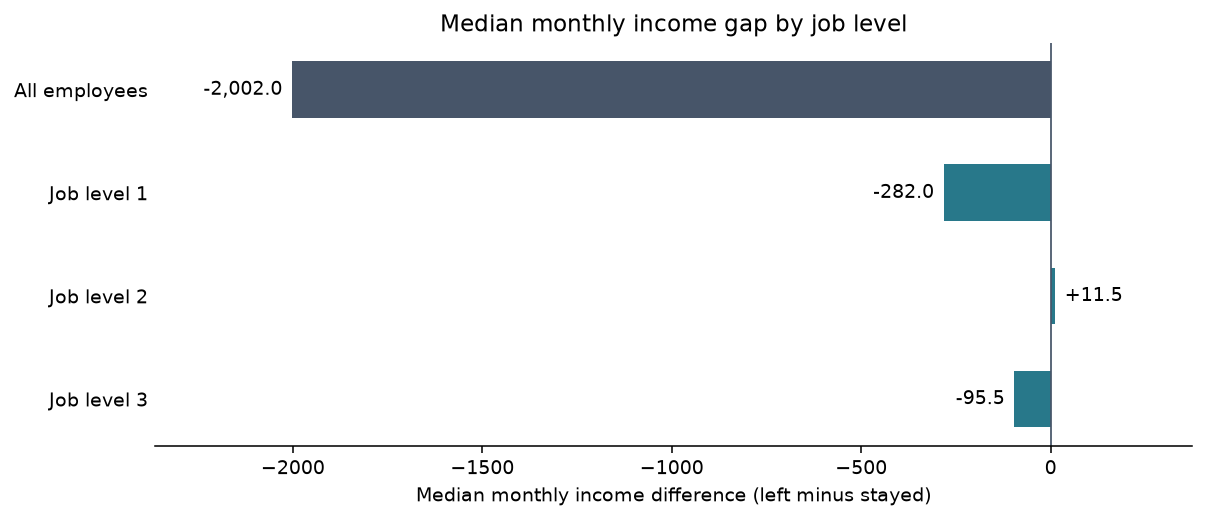

In [12]:
income_by_level = eda.pivot_table(
    index="JobLevel", columns="Attrition", values="MonthlyIncome", aggfunc="median"
).rename(columns={"No": "Stayed", "Yes": "Left"})
level_profile = summarize_attrition("JobLevel").join(income_by_level.add_prefix("Median income · "))
display(level_profile.round(1))

largest_levels = level_profile["Employees"].nlargest(3).index.sort_values()
level_medians = income_by_level.loc[largest_levels]
level_gaps = level_medians["Left"] - level_medians["Stayed"]
overall_gap = medians.loc["Yes", "MonthlyIncome"] - medians.loc["No", "MonthlyIncome"]
income_gaps = [overall_gap, *level_gaps]

fig, ax = plt.subplots(figsize=(8.5, 3.6), dpi=140, layout="constrained")
bars = ax.barh(
    ["All employees", *(f"Job level {level}" for level in largest_levels)],
    income_gaps,
    color=["#475569", *["#28788a"] * len(level_gaps)],
    height=0.55,
)
ax.bar_label(bars, labels=[f"{gap:+,.1f}" for gap in income_gaps], padding=5)
ax.axvline(0, color="#475569", linewidth=0.9)
ax.invert_yaxis()
ax.margins(x=0.18)
ax.set(title="Median monthly income gap by job level", xlabel="Median monthly income difference (left minus stayed)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.show()

The overall median income gap was 2,002. In job levels 1–3, the absolute gaps were 282, 11.5, and 95.5. Job level 1 accounted for 60.3% of departures and 32.4% of employees who stayed. That difference in group composition matters when interpreting the overall gap. Job levels 4 and 5 each had five departures, so their medians are based on small groups.

## 3. Which groups have higher exit rates?

Each row shows how many employees left out of the total in that group. Read the percentage alongside those counts, especially for groups with few exits. Differences in rates alone do not establish an interaction in a logistic model.

In [13]:
role_summary = summarize_attrition("JobRole").sort_values("Attrition (%)", ascending=False)
display(role_summary.round(1))

group_features = [
    "OverTime", "BusinessTravel", "JobSatisfaction",
    "JobInvolvement", "WorkLifeBalance", "StockOptionLevel", "TenureBand",
]
group_summaries = pd.concat(
    [summarize_attrition(feature) for feature in group_features],
    keys=group_features,
    names=["Feature", "Group"],
)
display(group_summaries.round(1))

,Employees,Employees who left,Attrition (%),Why read this rate with care?
JobRole,,,,
Sales Representative,83,33,39.8,—
Laboratory Technician,259,62,23.9,—
Human Resources,52,12,23.1,—
Sales Executive,326,57,17.5,—
Research Scientist,292,47,16.1,—
Manufacturing Director,145,10,6.9,—
Healthcare Representative,131,9,6.9,—
Manager,102,5,4.9,—
Research Director,80,2,2.5,only 2 left


Employees  Employees who left  \
Feature          Group                                              
OverTime         No                      1054                 110   
                 Yes                      416                 127   
BusinessTravel   Non-Travel               150                  12   
                 Travel_Frequently        277                  69   
                 Travel_Rarely           1043                 156   
JobSatisfaction  1                        289                  66   
                 2                        280                  46   
                 3                        442                  73   
                 4                        459                  52   
JobInvolvement   1                         83                  28   
                 2                        375                  71   
                 3                        868                 125   
                 4                        144                  13   
WorkLifeBalance  1                         80                  25   
                 2                        344                  58   
                 3                        893                 127   
                 4                        153                  27   
StockOptionLevel 0                        631                 154   
                 1                        596                  56   
                 2                        158                  12   
                 3                         85                  15   
TenureBand       0–2                      342                 102   
                 3–5                      434                  60   
                 6–10                     448                  55   
                 11+                      246                  20   

                                    Attrition (%)  \
Feature          Group                              
OverTime         No                          10.4   
                 Yes                         30.5   
BusinessTravel   Non-Travel                   8.0   
                 Travel_Frequently           24.9   
                 Travel_Rarely               15.0   
JobSatisfaction  1                           22.8   
                 2                           16.4   
                 3                           16.5   
                 4                           11.3   
JobInvolvement   1                           33.7   
                 2                           18.9   
                 3                           14.4   
                 4                            9.0   
WorkLifeBalance  1                           31.2   
                 2                           16.9   
                 3                           14.2   
                 4                           17.6   
StockOptionLevel 0                           24.4   
                 1                            9.4   
                 2                            7.6   
                 3                           17.6   
TenureBand       0–2                         29.8   
                 3–5                         13.8   
                 6–10                        12.3   
                 11+                          8.1   

                                   Why read this rate with care?  
Feature          Group                                            
OverTime         No                                            —  
                 Yes                                           —  
BusinessTravel   Non-Travel                                    —  
                 Travel_Frequently                             —  
                 Travel_Rarely                                 —  
JobSatisfaction  1                                             —  
                 2                                             —  
                 3                                             —  
                 4                                             —  
Job

### Compare stock option levels within marital-status groups

Show group sizes, the number of employees who left, and attrition rates for the combinations present in the data.

In [14]:
stock_options_by_marital = summarize_attrition(["MaritalStatus", "StockOptionLevel"])
display(stock_options_by_marital.round(1))

Employees  Employees who left  Attrition (%)  \
MaritalStatus StockOptionLevel                                                 
Divorced      0                         8                   3           37.5   
              1                       195                  18            9.2   
              2                        75                   5            6.7   
              3                        49                   7           14.3   
Married       0                       153                  31           20.3   
              1                       401                  38            9.5   
              2                        83                   7            8.4   
              3                        36                   8           22.2   
Single        0                       470                 120           25.5   

                                 Why read this rate with care?  
MaritalStatus StockOptionLevel                                  
Divorced      0                 only 8 employees · only 3 left  
              1                                              —  
              2                                              —  
              3                                              —  
Married       0                                              —  
              1                                              —  
              2                                              —  
              3                                              —  
Single        0                                              —

All 470 employees recorded as single are in stock option level 0. Among married employees, attrition was 20.3% at level 0 (31 of 153) and 9.5% at level 1 (38 of 401). Both comparisons describe observed associations in the dataset.

### Compare overtime within tenure bands

Compare attrition rates within each tenure band. The two share columns show how much of the workforce and how many of the employees who left come from each group.

In [15]:
tenure_overtime = summarize_attrition(["TenureBand", "OverTime"])
tenure_overtime["Workforce share (%)"] = 100 * tenure_overtime["Employees"] / len(eda)
tenure_overtime["Share of all who left (%)"] = (
    100 * tenure_overtime["Employees who left"] / attrition_counts.loc["Yes"]
)
display(tenure_overtime.round(1))

Employees  Employees who left  Attrition (%)  \
TenureBand OverTime                                                 
0–2        No              238                  49           20.6   
           Yes             104                  53           51.0   
3–5        No              307                  24            7.8   
           Yes             127                  36           28.3   
6–10       No              328                  24            7.3   
           Yes             120                  31           25.8   
11+        No              181                  13            7.2   
           Yes              65                   7           10.8   

                    Why read this rate with care?  Workforce share (%)  \
TenureBand OverTime                                                      
0–2        No                                   —                 16.2   
           Yes                                  —                  7.1   
3–5        No                                   —                 20.9   
           Yes                                  —                  8.6   
6–10       No                                   —                 22.3   
           Yes                                  —                  8.2   
11+        No                                   —                 12.3   
           Yes                                  —                  4.4   

                     Share of all who left (%)  
TenureBand OverTime                             
0–2        No                             20.7  
           Yes                            22.4  
3–5        No                             10.1  
           Yes                            15.2  
6–10       No                             10.1  
           Yes                            13.1  
11+        No                              5.5  
           Yes                             3.0

### Does the overtime gap differ across job levels?

Level 1 has the largest absolute gap. Levels 4 and 5 have only two or three exits per overtime group. Differences in percentage points can occur even with a common overtime effect on log-odds.

In [16]:
display(summarize_attrition(["JobLevel", "OverTime"]).round(1))

Employees  Employees who left  Attrition (%)  \
JobLevel OverTime                                                 
1        No              387                  61           15.8   
         Yes             156                  82           52.6   
2        No              388                  26            6.7   
         Yes             146                  26           17.8   
3        No              155                  19           12.3   
         Yes              63                  13           20.6   
4        No               73                   2            2.7   
         Yes              33                   3            9.1   
5        No               51                   2            3.9   
         Yes              18                   3           16.7   

                     Why read this rate with care?  
JobLevel OverTime                                   
1        No                                      —  
         Yes                                     —  
2        No                                      —  
         Yes                                     —  
3        No                                      —  
         Yes                                     —  
4        No                            only 2 left  
         Yes                           only 3 left  
5        No                            only 2 left  
         Yes       only 18 employees · only 3 left

### Which features should we test on training data?

Use the same stratified training employees as the model notebooks. Compare exit rates by age band to check whether attrition changes linearly with age. Then compare employees with zero vs. at least one completed year with their manager **within the same company-tenure band**. A recorded zero can reflect a new hire or a manager change.

In [17]:
model_train, _ = train_test_split(eda, test_size=0.20, stratify=eda["LeftCompany"], random_state=42)
print(f"Training employees only: {len(model_train):,}")
display(summarize_attrition("AgeBand", model_train).round(1))
display(summarize_attrition(["TenureBand", "ManagerTenure"], model_train).round(1))

Training employees only: 1,176


,Employees,Employees who left,Attrition (%),Why read this rate with care?
AgeBand,,,,
≤24,77,33,42.9,—
25–34,447,91,20.4,—
35–44,391,39,10.0,—
45–54,205,19,9.3,—
55+,56,8,14.3,—


Employees  Employees who left  Attrition (%)  \
TenureBand ManagerTenure                                                      
0–2        0 completed years         162                  63           38.9   
           1+ completed years        104                  23           22.1   
3–5        0 completed years          20                   5           25.0   
           1+ completed years        329                  38           11.6   
6–10       0 completed years          18                   3           16.7   
           1+ completed years        346                  43           12.4   
11+        0 completed years           3                   1           33.3   
           1+ completed years        194                  14            7.2   

                                                Why read this rate with care?  
TenureBand ManagerTenure                                                       
0–2        0 completed years                                                —  
           1+ completed years                                               —  
3–5        0 completed years                                only 20 employees  
           1+ completed years                                               —  
6–10       0 completed years                  only 18 employees · only 3 left  
           1+ completed years                                               —  
11+        0 completed years   only 3 employees · only 1 left · only 2 stayed  
           1+ completed years                                               —

### Plot the strongest group differences

The role chart labels each bar with its rate and the number who left out of the total number of employees in the role. The dashed line marks the overall attrition rate in both charts.

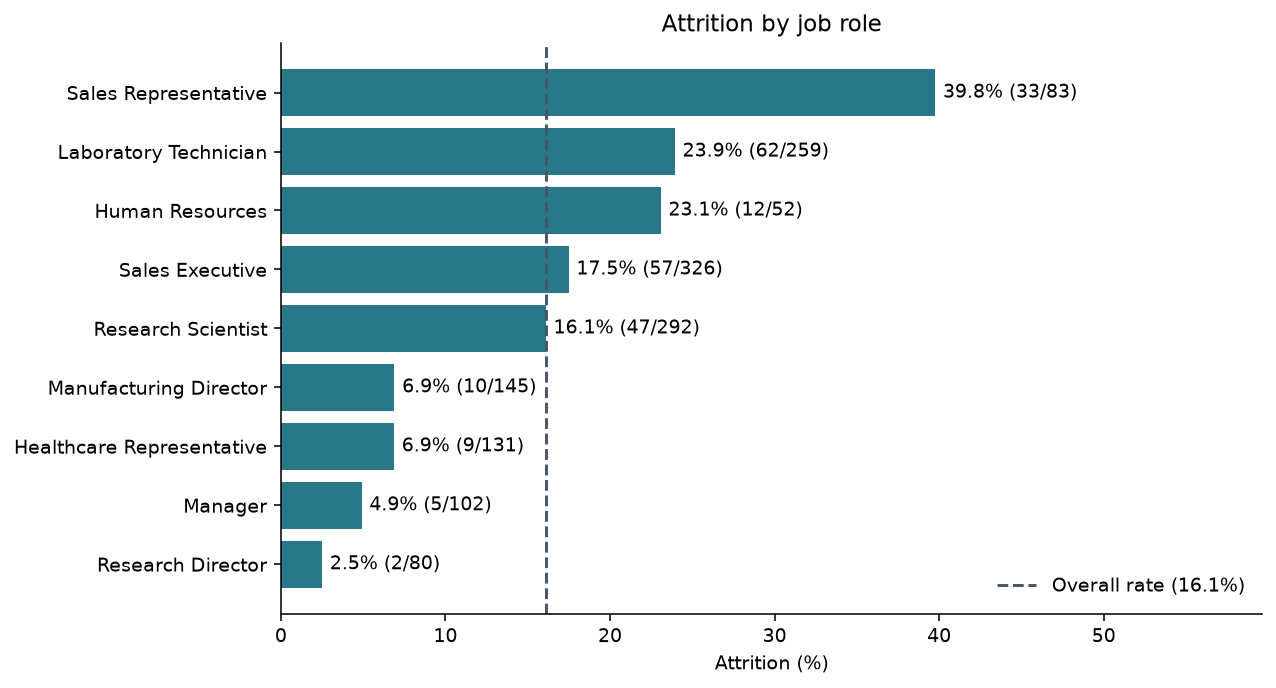

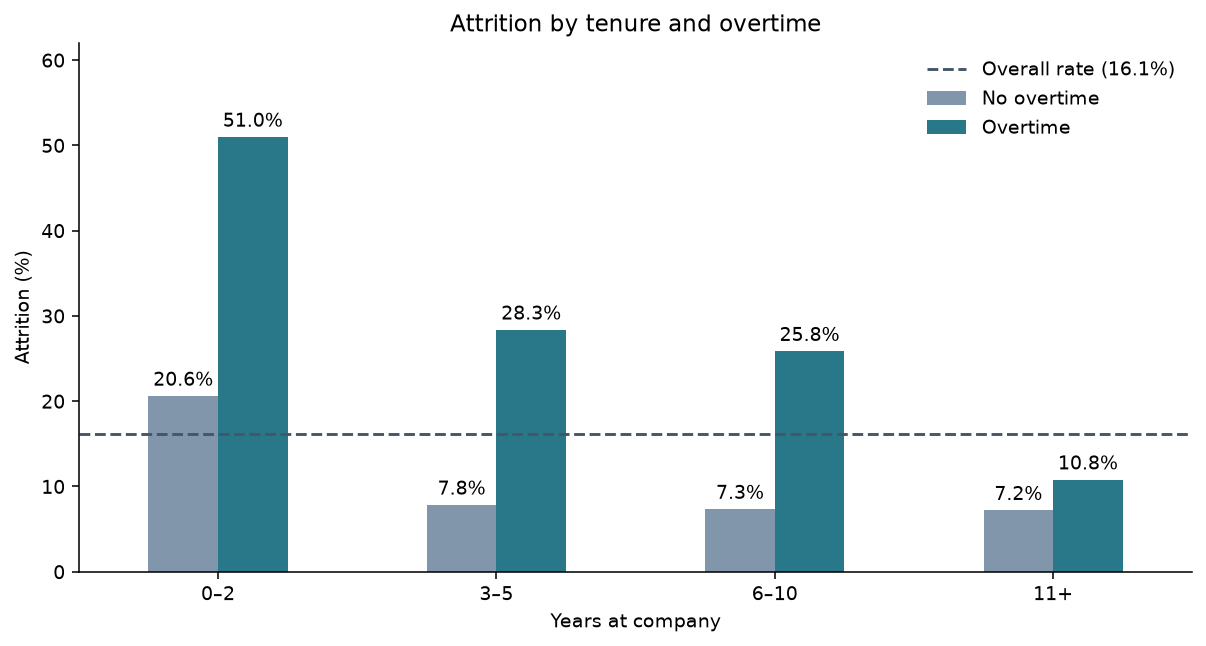

In [18]:
roles_by_rate = role_summary.sort_values("Attrition (%)")
role_rates = roles_by_rate["Attrition (%)"]
fig, role_ax = plt.subplots(figsize=(9, 4.8), dpi=140, layout="constrained")

role_bars = role_ax.barh(role_rates.index, role_rates, color="#28788a")
role_labels = [
    f"{rate:.1f}% ({employees_who_left}/{employees})"
    for rate, employees_who_left, employees in roles_by_rate[["Attrition (%)", "Employees who left", "Employees"]]
    .itertuples(index=False, name=None)
]
role_ax.bar_label(role_bars, labels=role_labels, padding=4)
role_ax.axvline(
    overall_rate, color="#475569", linestyle="--", label=f"Overall rate ({overall_rate:.1f}%)"
)
role_ax.set(title="Attrition by job role", xlabel="Attrition (%)", xlim=(0, role_rates.max() * 1.5))
role_ax.legend(loc="lower right", frameon=False)
role_ax.spines[["top", "right"]].set_visible(False)
plt.show()

overtime_rates = tenure_overtime["Attrition (%)"].unstack("OverTime").rename(
    columns={"No": "No overtime", "Yes": "Overtime"}
)
fig, tenure_ax = plt.subplots(figsize=(8.5, 4.5), dpi=140, layout="constrained")

overtime_rates.plot.bar(ax=tenure_ax, color=["#8196aa", "#28788a"], rot=0)
for bars in tenure_ax.containers:
    tenure_ax.bar_label(bars, fmt="%.1f%%", padding=3)
tenure_ax.axhline(
    overall_rate, color="#475569", linestyle="--", label=f"Overall rate ({overall_rate:.1f}%)"
)
tenure_ax.set(
    title="Attrition by tenure and overtime",
    xlabel="Years at company",
    ylabel="Attrition (%)",
    ylim=(0, 62),
)
tenure_ax.legend(loc="upper right", frameon=False)
tenure_ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. What carries over to the model?

The final model is **XGBoost** ([02_modeling.ipynb](02_modeling.ipynb)). We chose a tree model over logistic regression because a logistic regression can already be read from its coefficients, so LIME would add little. The earlier logistic regression notebooks turned several of the points below into hand-built features. A tree model learns them from the raw columns.

- **237 of 1,470 employees left (16.1%).** At job level 1 the rate was 52.6% with overtime (82/156) and 15.8% without (61/387). Among employees with 0–2 years at the company who worked overtime, 53/104 left (51.0%). Because only one in six employees left, the model uses class weights, and accuracy is not a useful measure. In the logistic regression experiments, explicit overtime interactions gave no stable gain. The tuned XGBoost model consists of single-feature trees and therefore models no interactions either.
- **Job level explains part of the observed income gap.** Median monthly income differed by 2,002 overall and by at most 282 within the three largest levels. The logistic regression experiments used income relative to the median for the job level. XGBoost receives job level and monthly income as separate columns.
- **Ordered codes can have uneven effects.** Across work-life balance levels 1–4, exit rates were 31.2%, 16.9%, 14.2% and 17.6%. Trees can split an ordered code at any level, so XGBoost keeps these codes as numbers without separate indicators. In all 1,470 rows performance rating equals 3 below a 20% salary increase and 4 above or at it. The rating therefore adds no information beyond the pay increase.
- **Two hypotheses from the training table.** Attrition was 42.9% at age 24 or younger (33/77), around 10% at ages 35–54, and 14.3% at 55+ (8/56). Among employees with 0–2 years at the company, the rate was 38.9% with zero completed manager years (63/162) and 22.1% with at least one (23/104). The zero-year groups at longer company tenure contain only 3–20 people. The logistic regression experiments tested a curved age effect (no gain) and a zero-manager-years indicator (small gain). XGBoost can represent both patterns directly from `Age` and `YearsWithCurrManager`.

These are associations in a snapshot. The data contain neither the date management relationships started nor the reason for an exit.